In [2]:
# Imports, seed, and device: CUDA on Colab, MPS on Apple Silicon, otherwise CPU.
import contextlib
import math
import time
import urllib.request
from dataclasses import asdict, dataclass
from pathlib import Path

import torch
import torch.nn as nn
from torch.nn import functional as F

torch.manual_seed(1337)
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
print("device:", device)

device: cuda


In [3]:
# Download the complete works of Shakespeare (Project Gutenberg #100), keep only the text between
# Gutenberg's START/END markers, and turn curly quotes into straight ones so typed prompts match.
URL = "https://www.gutenberg.org/cache/epub/100/pg100.txt"
path = Path("data/shakespeare.txt")
if not path.exists():
    path.parent.mkdir(exist_ok=True)
    urllib.request.urlretrieve(URL, path)

raw = path.read_text(encoding="utf-8-sig")
start = raw.index("\n", raw.index("*** START OF")) + 1
end = raw.index("*** END OF")
text = raw[start:end].replace("\r\n", "\n").strip()
text = text.translate(str.maketrans({"’": "'", "‘": "'", "“": '"', "”": '"'}))

print(f"{len(text):,} characters")
print(text[10_000:10_500])

5,359,342 characters
arths, or seasons' quality,
Nor can I fortune to brief minutes tell;
Pointing to each his thunder, rain and wind,
Or say with princes if it shall go well
By oft predict that I in heaven find.
But from thine eyes my knowledge I derive,
And constant stars in them I read such art
As truth and beauty shall together thrive
If from thyself, to store thou wouldst convert:
  Or else of thee this I prognosticate,
  Thy end is truth's and beauty's doom and date.


                    15

When I consider e


In [4]:
# Character-level tokenizer: every distinct character is one token.
chars = sorted(set(text))
vocab_size = len(chars)
stoi = {c: i for i, c in enumerate(chars)}


def encode(s):
    return [stoi[c] for c in s]


def decode(ids):
    return "".join(chars[i] for i in ids)


assert decode(encode(text[:10_000])) == text[:10_000]
print(vocab_size, "tokens:", repr("".join(chars)))

97 tokens: '\t\n !"&\'()*,-.0123456789:;?ABCDEFGHIJKLMNOPQRSTUVWXYZ[]_abcdefghijklmnopqrstuvwxyzÀÆÇÉàâæçèéêëîœ—…'


In [5]:
# 90/10 train/val split. A batch is random windows of block_size characters;
# the target is the same window shifted one character to the right.
data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9 * len(data))
train_data, val_data = data[:n], data[n:]


def get_batch(split, batch_size, block_size):
    d = train_data if split == "train" else val_data
    ix = torch.randint(len(d) - block_size, (batch_size,))
    x = torch.stack([d[i:i + block_size] for i in ix])
    y = torch.stack([d[i + 1:i + block_size + 1] for i in ix])
    return x.to(device), y.to(device)


x, y = get_batch("train", 4, 8)
assert x.shape == y.shape == (4, 8)
assert torch.equal(x[:, 1:], y[:, :-1])  # targets are inputs shifted by one

In [6]:
# GPT: token + position embeddings -> n_layer pre-norm transformer blocks (causal multi-head
# self-attention + MLP, each with a residual) -> LayerNorm -> output head tied to the token embedding.
# Attention takes an optional KV cache (keys/values of earlier positions), so generation only has to
# run the newest token through the model.
@dataclass
class GPTConfig:
    vocab_size: int
    block_size: int = 256
    n_layer: int = 6
    n_head: int = 6
    n_embd: int = 384
    dropout: float = 0.2


class CausalSelfAttention(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        assert cfg.n_embd % cfg.n_head == 0
        self.n_head = cfg.n_head
        self.qkv = nn.Linear(cfg.n_embd, 3 * cfg.n_embd, bias=False)
        self.proj = nn.Linear(cfg.n_embd, cfg.n_embd, bias=False)
        self.attn_drop = nn.Dropout(cfg.dropout)
        self.resid_drop = nn.Dropout(cfg.dropout)
        self.register_buffer("mask", torch.tril(torch.ones(cfg.block_size, cfg.block_size, dtype=torch.bool)))

    def forward(self, x, cache=None):
        B, T, C = x.shape
        q, k, v = self.qkv(x).split(C, dim=2)
        # (B, T, C) -> (B, n_head, T, head_size)
        q, k, v = (t.view(B, T, self.n_head, C // self.n_head).transpose(1, 2) for t in (q, k, v))
        if cache is not None:
            # keys/values of earlier positions go in front of the new ones
            k = torch.cat([cache[0], k], dim=2)
            v = torch.cat([cache[1], v], dim=2)
        S = k.size(2)  # past + current positions
        att = (q @ k.transpose(-2, -1)) / math.sqrt(k.size(-1))
        # the new queries sit at positions S-T..S-1, each sees keys up to itself
        att = att.masked_fill(~self.mask[S - T:S, :S], float("-inf"))
        att = self.attn_drop(F.softmax(att, dim=-1))
        y = (att @ v).transpose(1, 2).contiguous().view(B, T, C)
        return self.resid_drop(self.proj(y)), (k, v)


class Block(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.ln1 = nn.LayerNorm(cfg.n_embd)
        self.attn = CausalSelfAttention(cfg)
        self.ln2 = nn.LayerNorm(cfg.n_embd)
        self.mlp = nn.Sequential(
            nn.Linear(cfg.n_embd, 4 * cfg.n_embd),
            nn.GELU(),
            nn.Linear(4 * cfg.n_embd, cfg.n_embd),
            nn.Dropout(cfg.dropout),
        )

    def forward(self, x, cache=None):
        a, cache = self.attn(self.ln1(x), cache)
        x = x + a
        x = x + self.mlp(self.ln2(x))
        return x, cache


class GPT(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.n_embd)
        self.pos_emb = nn.Embedding(cfg.block_size, cfg.n_embd)
        self.drop = nn.Dropout(cfg.dropout)
        self.blocks = nn.ModuleList(Block(cfg) for _ in range(cfg.n_layer))
        self.ln_f = nn.LayerNorm(cfg.n_embd)
        self.head = nn.Linear(cfg.n_embd, cfg.vocab_size, bias=False)
        self.head.weight = self.tok_emb.weight  # tied embeddings
        self.apply(self._init_weights)

    def _init_weights(self, m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
        if isinstance(m, nn.Linear) and m.bias is not None:
            nn.init.zeros_(m.bias)

    def forward(self, idx, targets=None, caches=None):
        B, T = idx.shape
        past = 0 if caches is None else caches[0][0].size(2)
        assert past + T <= self.cfg.block_size, "sequence longer than block_size"
        pos = torch.arange(past, past + T, device=idx.device)
        x = self.drop(self.tok_emb(idx) + self.pos_emb(pos))
        new_caches = []
        for i, block in enumerate(self.blocks):
            x, c = block(x, None if caches is None else caches[i])
            new_caches.append(c)
        logits = self.head(self.ln_f(x))
        loss = None if targets is None else F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss, new_caches

In [7]:
# Check: the causal mask works, so changing later tokens never changes outputs at earlier positions.
tiny = GPTConfig(vocab_size=vocab_size, block_size=64, n_layer=2, n_head=2, n_embd=32, dropout=0.0)
m = GPT(tiny).to(device).eval()
a = torch.randint(vocab_size, (1, 16), device=device)
b = a.clone()
b[0, 10:] = torch.randint(vocab_size, (6,), device=device)
with torch.no_grad():
    la, lb = m(a)[0], m(b)[0]
assert torch.allclose(la[0, :10], lb[0, :10], atol=1e-4)

In [8]:
# Sampling: temperature=0 is greedy; otherwise temperature scaling with optional top-k / top-p filtering.
# generate re-runs the whole window every step; generate_cached runs the prompt once, then feeds
# one token at a time and reuses the KV cache.
def sample_next(logits, temperature=1.0, top_k=None, top_p=None):
    if temperature == 0:
        return logits.argmax(dim=-1, keepdim=True)
    logits = logits / temperature
    if top_k is not None:
        kth = torch.topk(logits, min(top_k, logits.size(-1))).values[:, [-1]]
        logits = logits.masked_fill(logits < kth, float("-inf"))
    if top_p is not None:
        sorted_logits, sorted_idx = torch.sort(logits, descending=True)
        probs = F.softmax(sorted_logits, dim=-1)
        # drop a token once the tokens before it already cover top_p (the top one always stays)
        sorted_logits[probs.cumsum(dim=-1) - probs >= top_p] = float("-inf")
        logits = torch.full_like(logits, float("-inf")).scatter(-1, sorted_idx, sorted_logits)
    return torch.multinomial(F.softmax(logits, dim=-1), num_samples=1)


@torch.no_grad()
def generate(model, idx, max_new_tokens, **sampling):
    for _ in range(max_new_tokens):
        logits, _, _ = model(idx[:, -model.cfg.block_size:])
        idx = torch.cat([idx, sample_next(logits[:, -1], **sampling)], dim=1)
    return idx


@torch.no_grad()
def generate_cached(model, idx, max_new_tokens, **sampling):
    bs = model.cfg.block_size
    logits, _, caches = model(idx[:, -bs:])
    for _ in range(max_new_tokens):
        nxt = sample_next(logits[:, -1], **sampling)
        idx = torch.cat([idx, nxt], dim=1)
        if caches[0][0].size(2) == bs:
            # learned absolute positions can't slide, so a full cache is rebuilt from the last half window
            # (output differs from `generate` past block_size); rotary embeddings would allow a rolling cache
            logits, _, caches = model(idx[:, -(bs // 2):])
        else:
            logits, _, caches = model(nxt, caches=caches)
    return idx

In [9]:
# Checks: cached and uncached greedy decoding agree (within block_size),
# and top-k never picks outside the k best tokens.
prompt = torch.tensor([encode("ROMEO:")], device=device)
assert torch.equal(generate(m, prompt, 40, temperature=0), generate_cached(m, prompt, 40, temperature=0))

logits = torch.randn(1000, vocab_size)
picked = sample_next(logits, top_k=5)
assert (picked == torch.topk(logits, 5).indices).any(dim=1).all()
print("all checks passed")

all checks passed


In [10]:
# Training config for the ~10.77M param model. fp16 autocast + gradient scaling on CUDA only.
# Learning rate: linear warmup, then cosine decay to min_lr.
cfg = GPTConfig(vocab_size=vocab_size)

batch_size = 64
max_iters = 4000
lr, min_lr = 1e-3, 1e-4
warmup_iters = 200
grad_clip = 1.0
eval_interval = 250
eval_iters = 100

use_amp = device == "cuda"
amp = lambda: torch.autocast("cuda", dtype=torch.float16) if use_amp else contextlib.nullcontext()
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)


def get_lr(it):
    if it < warmup_iters:
        return lr * (it + 1) / warmup_iters
    progress = (it - warmup_iters) / max(1, max_iters - warmup_iters)
    return min_lr + 0.5 * (lr - min_lr) * (1 + math.cos(math.pi * progress))


# average loss over eval_iters random batches per split, with dropout off
@torch.no_grad()
def estimate_loss(model):
    model.eval()
    out = {}
    for split in ("train", "val"):
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            x, y = get_batch(split, batch_size, cfg.block_size)
            with amp():
                losses[k] = model(x, y)[1].item()
        out[split] = losses.mean().item()
    model.train()
    return out

In [11]:
# Training loop: AdamW, gradient clipping, train/val loss every eval_interval steps.
model = GPT(cfg).to(device)
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.2f}M params")
optimizer = torch.optim.AdamW(model.parameters(), lr=lr, betas=(0.9, 0.99))

log = []
t0 = time.time()
for it in range(max_iters):
    for group in optimizer.param_groups:
        group["lr"] = get_lr(it)
    if it % eval_interval == 0 or it == max_iters - 1:
        losses = estimate_loss(model)
        log.append((it, losses["train"], losses["val"]))
        print(f"step {it:5d} | train {losses['train']:.4f} | val {losses['val']:.4f} | {time.time() - t0:.0f}s")

    x, y = get_batch("train", batch_size, cfg.block_size)
    with amp():
        _, loss, _ = model(x, y)
    optimizer.zero_grad(set_to_none=True)
    scaler.scale(loss).backward()
    scaler.unscale_(optimizer)
    torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
    scaler.step(optimizer)
    scaler.update()

print(f"done in {(time.time() - t0) / 60:.1f} min")

10.77M params
step     0 | train 4.6364 | val 4.6385 | 10s
step   250 | train 2.2582 | val 2.2784 | 60s
step   500 | train 1.6993 | val 1.7623 | 113s
step   750 | train 1.4847 | val 1.6080 | 167s
step  1000 | train 1.3795 | val 1.5340 | 220s
step  1250 | train 1.3136 | val 1.4894 | 274s
step  1500 | train 1.2779 | val 1.4539 | 328s
step  1750 | train 1.2454 | val 1.4363 | 381s
step  2000 | train 1.2159 | val 1.4120 | 435s
step  2250 | train 1.1917 | val 1.3988 | 489s
step  2500 | train 1.1685 | val 1.3820 | 543s
step  2750 | train 1.1522 | val 1.3683 | 596s
step  3000 | train 1.1385 | val 1.3639 | 650s
step  3250 | train 1.1252 | val 1.3550 | 704s
step  3500 | train 1.1160 | val 1.3515 | 757s
step  3750 | train 1.1075 | val 1.3470 | 811s
step  3999 | train 1.1068 | val 1.3385 | 864s
done in 14.4 min


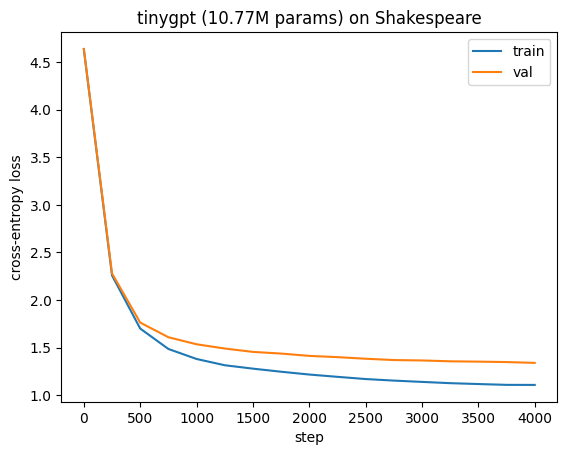

In [17]:
# Train/val loss recorded every 250 steps during training.
# Val flattening while train keeps falling is where more steps stop paying off.
import matplotlib.pyplot as plt

steps, train_loss, val_loss = zip(*log)
plt.plot(steps, train_loss, label="train")
plt.plot(steps, val_loss, label="val")
plt.xlabel("step")
plt.ylabel("cross-entropy loss")
plt.title("tinygpt (10.77M params) on Shakespeare")
plt.legend()
plt.show()

In [12]:
# Sample 500 characters from the trained model.
model.eval()
prompt = torch.tensor([encode("ROMEO:\n")], device=device)
print(decode(generate_cached(model, prompt, 500, temperature=0.8, top_k=50)[0].tolist()))

ROMEO:
Good morrow, good sir, no more. And all the suns i'
the mean of his life.

ANTONIO.
He's a good friend and sickness to his hand.

CLOTEN.
Why, I think thou hast won thee, but a word and bright him that he saw a way
may be undone me, that any person belongs to the question of an ox of a
cabit? Have I mine own patience, and the rest spirit? Is that so the woman and so
many is the most service? Is he for his mind and he would convey his uncle?

MISTRESS FORD.
I will drink you so much as the worst a


In [25]:
# KV cache speedup on the hardware this notebook is running on.
# On a GPU this small model is limited by kernel launch overhead, so the cache barely helps.
# On CPU, where the Hugging Face Space serves the model, cost grows with the number of
# tokens processed, so reusing cached keys/values gives a large speedup.
import copy
import platform
import subprocess

# Use the model trained above if it exists; otherwise load the published checkpoint (skips retraining).
if "model" not in globals():
    if not Path("shakespeare.pt").exists():
        urllib.request.urlretrieve("https://huggingface.co/hr5ht/tinygpt-shakespeare/resolve/main/shakespeare.pt", "shakespeare.pt")
    ckpt = torch.load("shakespeare.pt", map_location=device)
    model = GPT(GPTConfig(**ckpt["config"])).to(device).eval()
    model.load_state_dict(ckpt["model"])


def label(dev):
    if dev == "cuda":
        return torch.cuda.get_device_name(0).replace("Tesla ", "") + " GPU"
    chip = subprocess.run(["sysctl", "-n", "machdep.cpu.brand_string"], capture_output=True, text=True).stdout.strip()
    return chip + (" GPU" if dev == "mps" else " CPU")


def bench(m, dev, n=300):
    p = torch.tensor([encode("ROMEO.\n")], device=dev)
    generate_cached(m, p, 20, temperature=0.8, top_k=50).tolist()  # warm-up
    speeds = []
    for fn in (generate, generate_cached):
        t = time.time()
        fn(m, p, n, temperature=0.8, top_k=50).tolist()  # .tolist() waits for the device to finish
        speeds.append(n / (time.time() - t))
    return speeds


devices = [device] + (["cpu"] if platform.system() == "Darwin" else [])

print(f"{'hardware':15s} | {'no cache':>12s} | {'kv cache':>12s} | speedup")
for dev in devices:
    plain, cached = bench(copy.deepcopy(model).to(dev).eval(), dev)
    print(f"{label(dev):15s} | {plain:6.0f} tok/s | {cached:6.0f} tok/s | {cached / plain:4.1f}x")

hardware        |     no cache |     kv cache | speedup
T4 GPU          |    225 tok/s |    235 tok/s |  1.0x


In [14]:
# Save weights + config + vocabulary (everything needed to rebuild the model) and the loss log.
torch.save({"model": model.state_dict(), "config": asdict(cfg), "chars": chars}, "shakespeare.pt")
with open("losses.csv", "w") as f:
    f.write("step,train,val\n")
    f.writelines(f"{s},{tr:.4f},{va:.4f}\n" for s, tr, va in log)

In [15]:
# Reload the saved checkpoint and verify it: same vocabulary, identical greedy output to the trained
# model, and val loss under 2.0 (a uniform guess over 97 tokens scores ln(97) = 4.57).
ckpt = torch.load("shakespeare.pt", map_location=device)
reloaded = GPT(GPTConfig(**ckpt["config"])).to(device).eval()
reloaded.load_state_dict(ckpt["model"])
final_val = log[-1][2]

assert ckpt["chars"] == chars
assert torch.equal(generate_cached(model, prompt, 100, temperature=0), generate_cached(reloaded, prompt, 100, temperature=0))
assert final_val < 2.0, f"val loss {final_val:.3f} is too high, the model did not learn"

print(decode(generate_cached(reloaded, prompt, 300, temperature=0.8, top_k=50)[0].tolist()))
print()
print("=" * 60)
print("TRAINING SUCCESSFUL")
print(f"val loss {final_val:.3f} | {sum(p.numel() for p in reloaded.parameters()) / 1e6:.2f}M params | {(time.time() - t0) / 60:.1f} min since training started")
print("checkpoint reloads and generates the same text as the trained model")
print("=" * 60)

ROMEO:
Yet to keep till my lips, wherefore I shall call thee with
the wars of trencher.

FIRST SERVINGMAN.
That's a gentleman, and that will still take thee my cousin's
name. There is no more, Nedarus.

SECOND SERVINGMAN.
I'll fight a juggling strange and banishment.

THIRD SERVINGMAN.
Why, when I also swe

TRAINING SUCCESSFUL
val loss 1.338 | 10.77M params | 14.6 min since training started
checkpoint reloads and generates the same text as the trained model


In [16]:
# Upload the checkpoint and loss log to the Hugging Face Hub.
# The inference server (a Hugging Face Space) downloads the model from here at startup.
# The token is read with getpass, so it is never stored in the notebook.
import getpass
from huggingface_hub import HfApi

api = HfApi(token=getpass.getpass("HF write token: "))
repo_id = f"{api.whoami()['name']}/tinygpt-shakespeare"
api.create_repo(repo_id, exist_ok=True)
for f in ("shakespeare.pt", "losses.csv"):
    api.upload_file(path_or_fileobj=f, path_in_repo=f, repo_id=repo_id)
print(f"uploaded to https://huggingface.co/{repo_id}")

uploaded to https://huggingface.co/hr5ht/tinygpt-shakespeare
